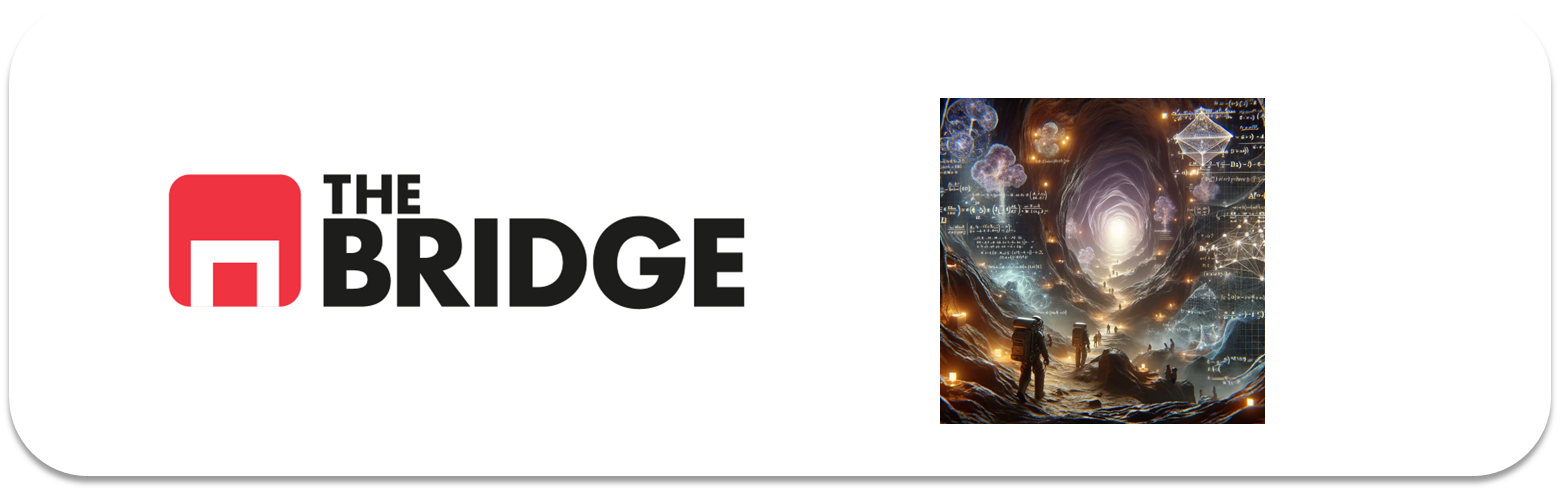

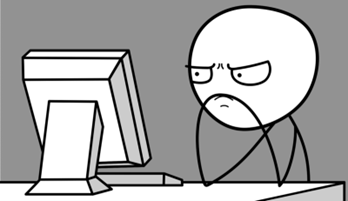

Para ejercitarte y afianzar lo aprendido sobre **Keras y DL**, completa los siguientes ejercicios. Recuerda que necesitarás datos que están en la carpeta `data` de la unidad
  
Las soluciones ya las tienes: intenta no mirarlas de primeras, pero no dejes de hacerlo cuando hayas terminado por si te pudieran aportar.

### Predecir eficiencia de gasolina

En este conjunto de ejercicios vamos a trabajar sobre el set de datos clásico [Auto MPG](https://archive.ics.uci.edu/ml/datasets/auto+mpg) para construir un modelo DL para predecir el consumo de vehículos de los años 70 y principios de los 80. Para ello, proporcionaremos al modelo una descripción de muchos automóviles de ese periodo. Esta descripción incluye atributos como: Cilindros, desplazamiento, potencia y peso.

El objetivo de este ejercicio es predecir el target miles per gallon (MPG), que vendría a representar las millas por galón de combustible.

Para la construcción del modelo vamos a utilizar Keras.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42) # Resultados reproducibles

### Ejercicio 1

Carga los datos en un dataframe, utilizando como nombre de columnas los siguientes:

```python
column_names = ['MPG','Cylinders','Displacement','Horsepower','Weight', 'Acceleration', 'Model Year', 'Origin']
``` 


*Nos han dado los datos en un fichero de texto, sobre el que no puedo hacer el típico read_csv, hmmm, tendremos que recordar el procesamiento de ficheros de texto para manipularlo y obtener el dataset*

In [2]:
df =  pd.read_csv("../data/Autos_data.txt")

In [3]:
df

,"18.0 8 307.0 130.0 3504. 12.0 70 1\t""chevrolet chevelle malibu"""
0,15.0 8 350.0 165.0 3693. 11...
1,18.0 8 318.0 150.0 3436. 11...
2,16.0 8 304.0 150.0 3433. 12...
3,17.0 8 302.0 140.0 3449. 10...
4,15.0 8 429.0 198.0 4341. 10...
...,...
392,27.0 4 140.0 86.00 2790. 15...
393,44.0 4 97.00 52.00 2130. 24...
394,32.0 4 135.0 84.00 2295. 11...
395,28.0 4 120.0 79.00 2625. 18...


In [4]:
column_names = ['MPG','Cylinders','Displacement','Horsepower','Weight', 'Acceleration', 'Model Year', 'Origin']
with open("../data/Autos_data.txt") as f:
    datos = f.read()

lista_datos = []

for linea in datos.split("\n"):
    # split() separa por espacios; el nombre del coche (última columna) queda fuera porque zip se corta en column_names
    datos = {clave.lower():dato for clave,dato in zip(column_names,linea.split())}
    lista_datos.append(datos)

df = pd.DataFrame(lista_datos)
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130.0,3504.,12.0,70,1
1,15.0,8,350.0,165.0,3693.,11.5,70,1
2,18.0,8,318.0,150.0,3436.,11.0,70,1
3,16.0,8,304.0,150.0,3433.,12.0,70,1
4,17.0,8,302.0,140.0,3449.,10.5,70,1
...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.00,2790.,15.6,82,1
394,44.0,4,97.00,52.00,2130.,24.6,82,2
395,32.0,4,135.0,84.00,2295.,11.6,82,1
396,28.0,4,120.0,79.00,2625.,18.6,82,1


### Ejercicio 2: Limpieza inicial

Echa un primer vistazo. Limpia columnas "raras". Deshazte de nulos (cuidado aquí), arregla el tipo de las features numéricas si fuera necesario. Haz una lista de las features categóricas que tuviéramos que convertir posteriormente. (Es antes del split pero no importa para este ejercicio)

In [5]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130.0,3504.,12.0,70,1
1,15.0,8,350.0,165.0,3693.,11.5,70,1
2,18.0,8,318.0,150.0,3436.,11.0,70,1
3,16.0,8,304.0,150.0,3433.,12.0,70,1
4,17.0,8,302.0,140.0,3449.,10.5,70,1
...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.00,2790.,15.6,82,1
394,44.0,4,97.00,52.00,2130.,24.6,82,2
395,32.0,4,135.0,84.00,2295.,11.6,82,1
396,28.0,4,120.0,79.00,2625.,18.6,82,1


*Weight claramente es una columna rara, la tenemos que limpiar*

In [6]:
df["weight"] = df["weight"].str.replace(".","").astype(int)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   mpg           398 non-null    object
 1   cylinders     398 non-null    object
 2   displacement  398 non-null    object
 3   horsepower    398 non-null    object
 4   weight        398 non-null    int32 
 5   acceleration  398 non-null    object
 6   model year    398 non-null    object
 7   origin        398 non-null    object
dtypes: int32(1), object(7)
memory usage: 23.4+ KB


*Parece que no hay nulos y hay muchas que parecen numéricas que están clasificadas como `object`. No parece que haya categóricas que convertir porque origin está codificada y cylinders también*

*Convirtamos todas a numéricas*

In [8]:
df = df.astype("float")

ValueError: could not convert string to float: '?'

*Vaya, hay valores raros: missings codificados con un interrogante (`?`) :-). Tenemos más trabajo del que esperábamos*

In [9]:
for col in df.columns:
    df[col] = df[col].apply(lambda row: row if str(row) != "?" else np.nan).astype("float") # Lo convertimos a nulo


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    float64
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    float64
 7   origin        398 non-null    float64
dtypes: float64(8)
memory usage: 25.0 KB


*Tenemos 6 nulos en horsepower, que tiramos como nos dice el enunciado*

In [11]:
df.dropna(inplace = True)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    float64
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    float64
 5   acceleration  392 non-null    float64
 6   model year    392 non-null    float64
 7   origin        392 non-null    float64
dtypes: float64(8)
memory usage: 27.6 KB


### Ejercicio 3

Antes de seguir nos informan que las etiquetas de "origin" corresponden a  USA para el 1, Europa para el 2 y Japón para el 3. Convierte origin a esos valores porque queremos tener el literal. Luego haz directamente un one-hot encoding de esa variable.  

*NOTA: el one-hot encoding podría hacerse sobre el dataset completo desde el principio, porque cada fila se codifica sin depender de las demás. Si normalmente esperamos es porque, hasta analizar las variables (y su relación con el target, que sólo debe estudiarse en train), no sabemos si nos interesará una codificación ordinal, un one-hot u otra transformación. Si tenemos claro que vamos a hacer one-hot, no hay problema en hacerlo antes del split. Eso sí, conviene prever una categoría "unknown" para los valores nuevos que puedan llegar en el futuro antes de reentrenar el modelo.*


In [13]:
df["origin"] = df["origin"].map( {1.0: "USA", 2.0: "Europe", 3.0: "Japan"})

In [14]:
df.origin.value_counts()

origin
USA       245
Japan      79
Europe     68
Name: count, dtype: int64

In [15]:
df = pd.get_dummies(df, columns = ["origin"], dtype = int)

In [16]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_Europe,origin_Japan,origin_USA
0,18.0,8.0,307.0,130.0,3504.0,12.0,70.0,0,0,1
1,15.0,8.0,350.0,165.0,3693.0,11.5,70.0,0,0,1
2,18.0,8.0,318.0,150.0,3436.0,11.0,70.0,0,0,1
3,16.0,8.0,304.0,150.0,3433.0,12.0,70.0,0,0,1
4,17.0,8.0,302.0,140.0,3449.0,10.5,70.0,0,0,1
...,...,...,...,...,...,...,...,...,...,...
393,27.0,4.0,140.0,86.0,2790.0,15.6,82.0,0,0,1
394,44.0,4.0,97.0,52.0,2130.0,24.6,82.0,1,0,0
395,32.0,4.0,135.0,84.0,2295.0,11.6,82.0,0,0,1
396,28.0,4.0,120.0,79.0,2625.0,18.6,82.0,0,0,1


### Ejercicio 4

Divide el dataset en un set de entrenamiento (train, 80%) y otro de pruebas (test, 20%).

Usaremos el set de pruebas en la evaluación final de nuestro modelo. Guarda el nombre de la columna target en una variable `target`.

NOTA: el resultado tiene que ser dos dataframes (train y test), con features y target juntos

In [17]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(df, train_size = 0.8, random_state = 42) # Usamos train_size en vez de test_size, para variar :-)

In [18]:
target = "mpg"

### Ejercicio 5

Inspecciona los datos. Revisa rápidamente la distribución conjunta del dataset de entrenamiento mediante un grid de gráficos

*Empezando por el target*

<Axes: xlabel='mpg', ylabel='Count'>

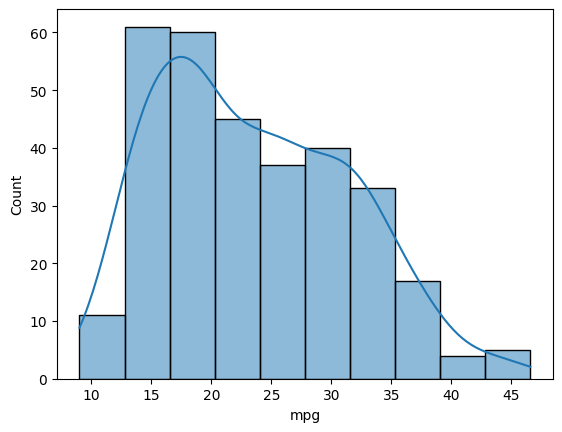

In [19]:
sns.histplot(data = train_set, x = target, kde = True)

*No es exactamente normal, pero no tiene mala "figura"*

*Veamos el resto con un pairplot. Aunque no son muchas columnas, son demasiadas para un único pairplot, así que lo partimos en dos*

In [20]:
features = [col for col in train_set.columns if col != target]
len(features)

9

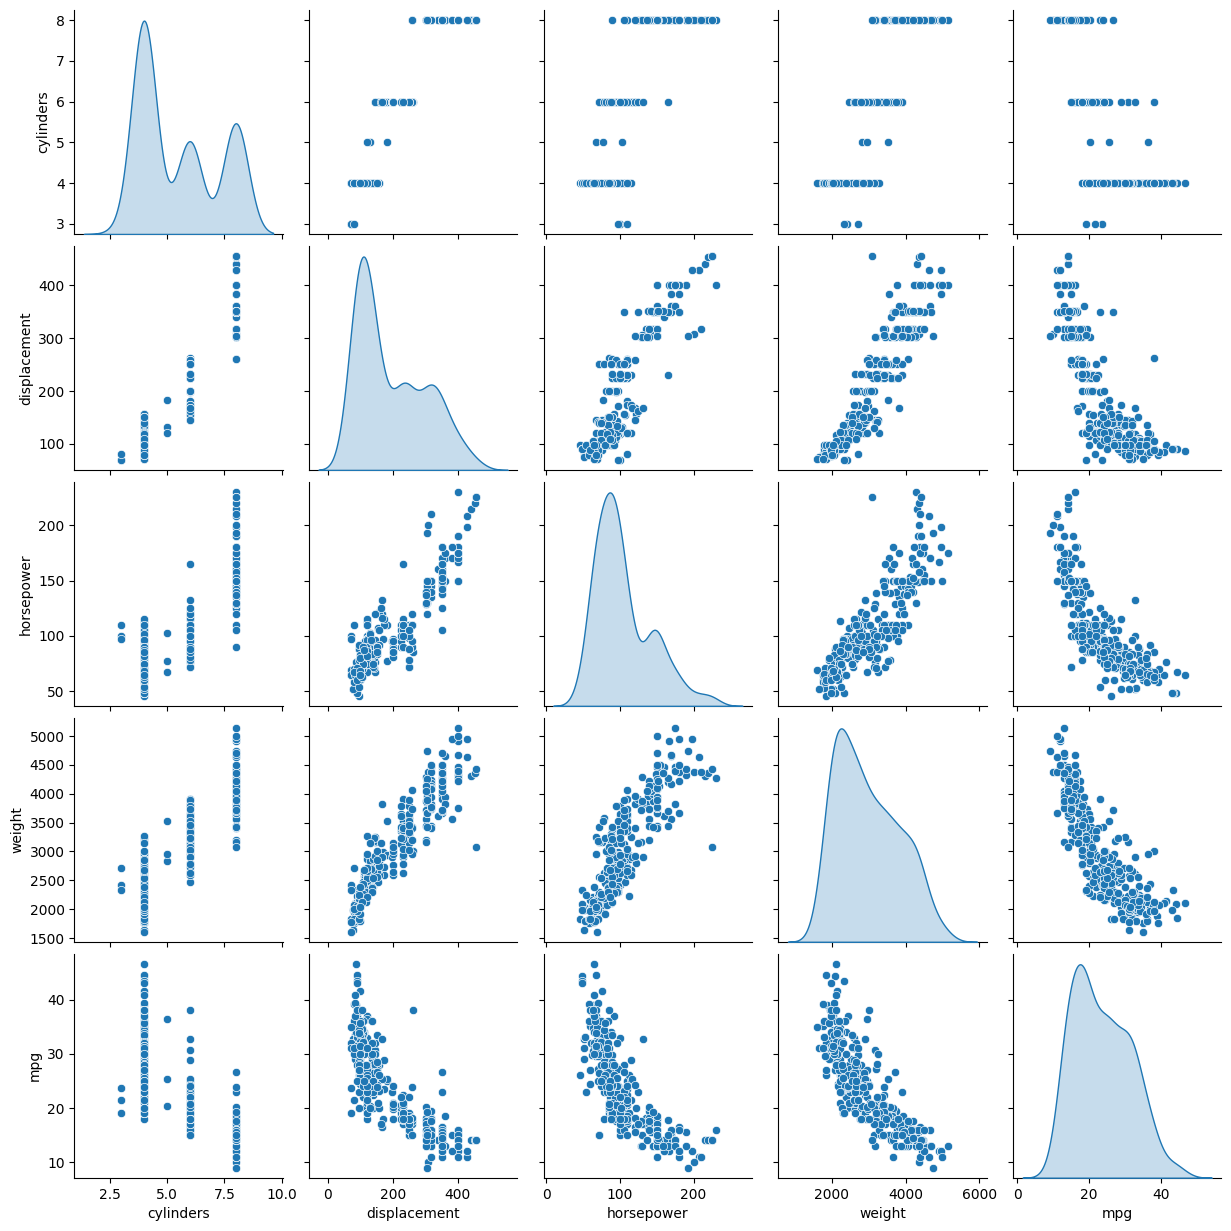

In [21]:
sns.pairplot(train_set[features[0:4]+[target]], diag_kind="kde");

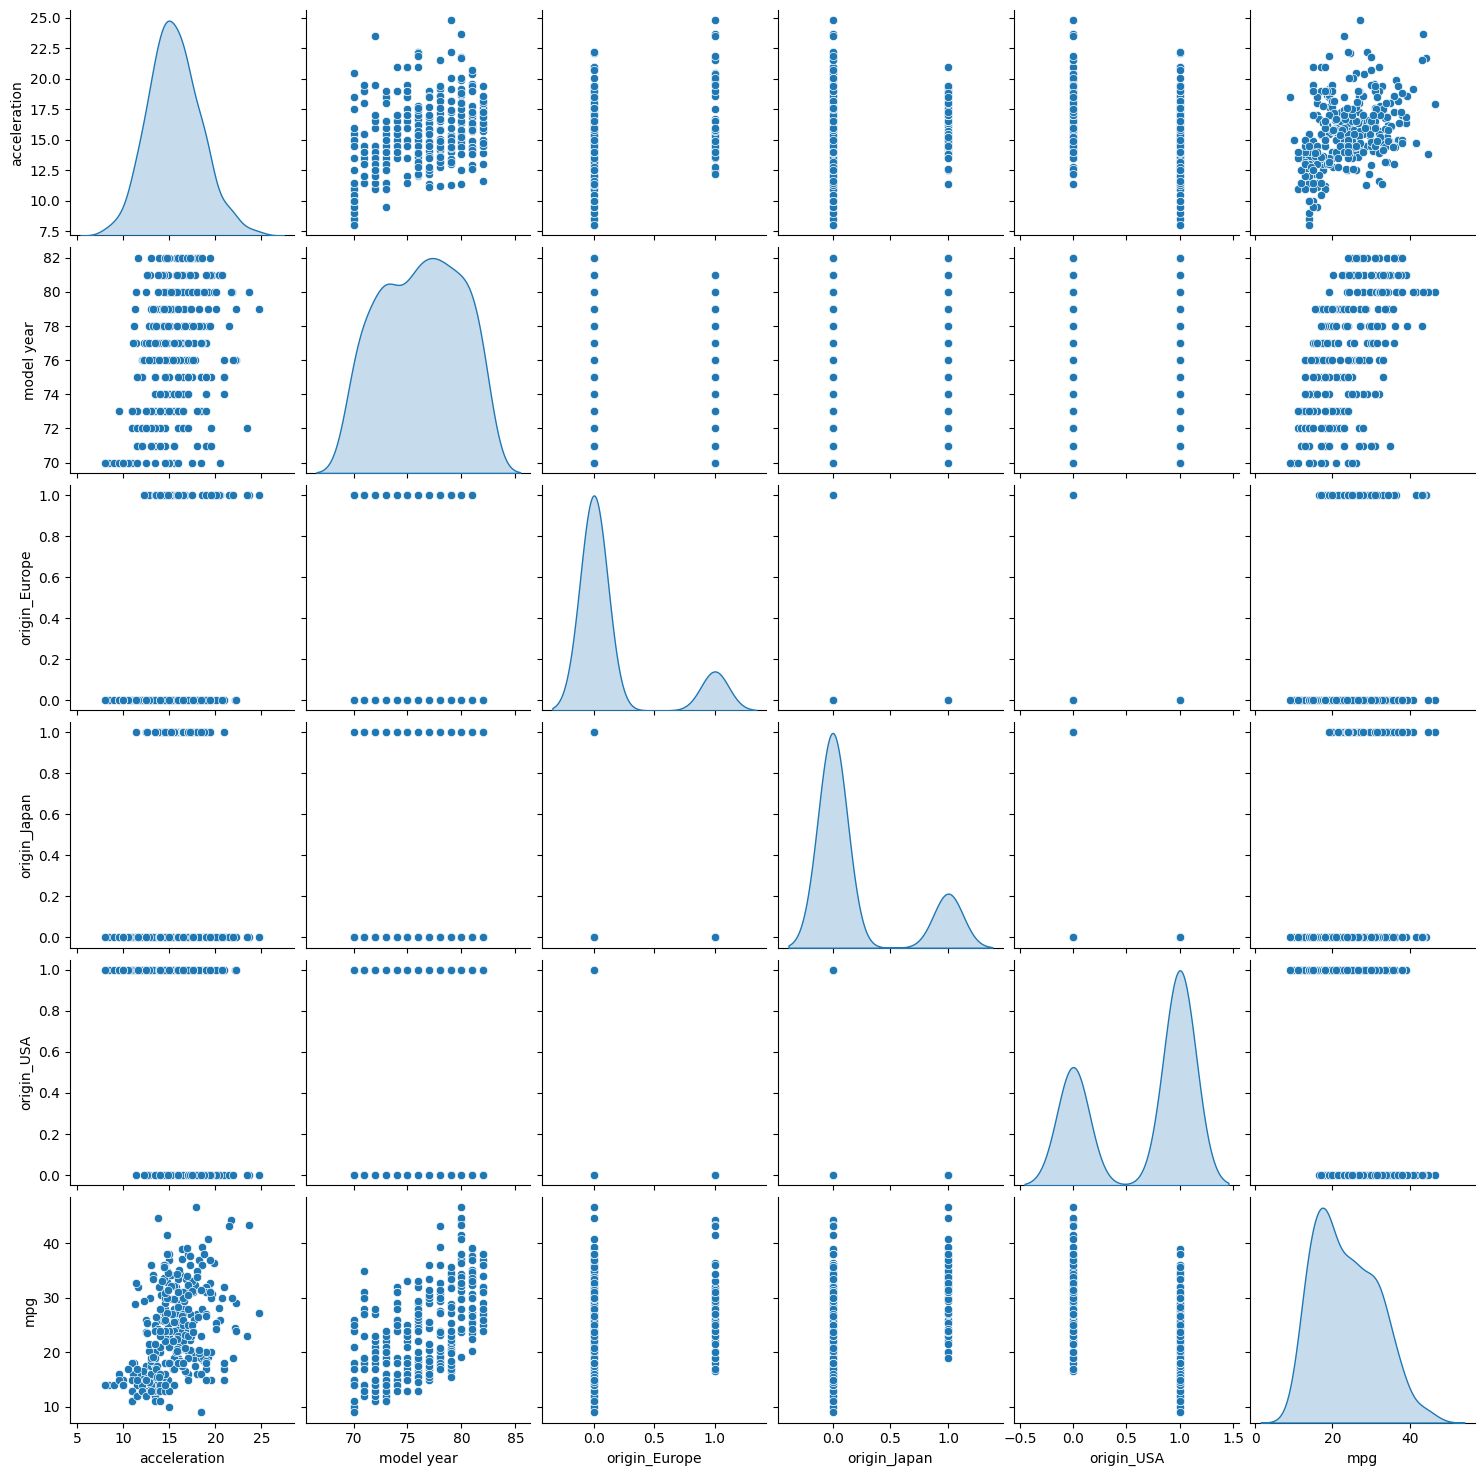

In [22]:
sns.pairplot(train_set[features[4:]+[target]], diag_kind="kde");

*Se ven claras correlaciones, algunas no lineales, entre varias de las variables, deberíamos quizá ser selectivos a la hora de escoger qué features priorizar para los modelos*

*Puedes hacerlo tú con calma; para este ejercicio nos quedaremos con todas*

*Hagamos también nuestro pequeño análisis de correlación bivariante:*

In [23]:
corr = train_set.corr()
np.abs(corr[target]).sort_values(ascending = False)

mpg              1.000000
weight           0.835568
displacement     0.811580
horsepower       0.782381
cylinders        0.780555
model year       0.590454
origin_USA       0.562162
origin_Japan     0.473004
acceleration     0.412048
origin_Europe    0.220038
Name: mpg, dtype: float64

*Son correlaciones bastante altas, así que esperamos que aporten. Para completar, veamos el heatmap*

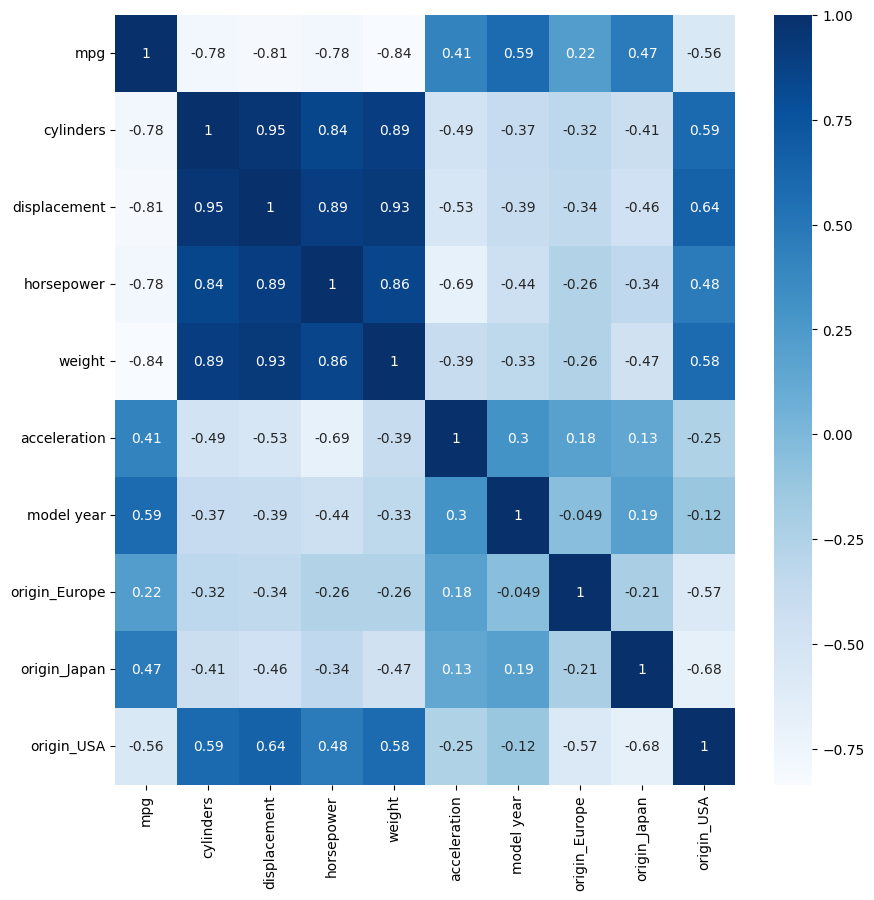

In [24]:
plt.figure(figsize= (10,10))
sns.heatmap(corr, annot = True, cmap = "Blues");

*Aquí se ve claramente ese cuadrado de altas correlaciones y alguna que otra curiosidad (como esa correlación negativa entre ser de USA y el MPG: los coches americanos recorren menos millas por galón, es decir, consumen más)*

### Ejercicio 6 

Independientemente de lo que hayas encontrado en el análisis anterior, vamos a utilizar todas las features y antes las vamos a escalar. Estandariza train y test.

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_set[features] = scaler.fit_transform(train_set[features])
test_set[features] = scaler.transform(test_set[features])

## El modelo

### Ejercicio 7: Construye el modelo con Keras

Construyamos nuestro modelo. Aquí, utilizaremos un modelo `secuencial` con dos capas ocultas densamente conectadas y una capa de salida que devuelve un único valor continuo. Es decir, un MLP con dos capas ocultas.

Por tanto, tendrá tres capas densas: una primera capa oculta con activación relu (empieza el modelo con `keras.Input(shape=(n_features,))` para indicarle el número de features), una segunda capa oculta también con relu y la capa de salida de regresión, con una única neurona. Pon las neuronas que consideres interesantes para las dos primeras capas (NOTA: En este caso partimos de pocas features, por lo que puede ser interesante poner como mínimo 2 o 3 veces el número de features para poder obtener unas pseudofeatures que intenten capturar las interrelaciones.)

Otros datos:

Para el compile utiliza un loss='mse'.

optimizer = `tf.keras.optimizers.RMSprop(0.001)`

Y en metrics añade en una lista el `mae` y `mse`.

Utiliza una aproximación en prisma (mismo número de unidades en las capas ocultas)

In [26]:
factor_expansion = 3
num_units = len(features) * factor_expansion

*Método 1, añadiendo las capas una a una con `add`*

In [27]:
model_add = keras.models.Sequential()

model_add.add(keras.Input(shape = (len(features),)))
model_add.add(keras.layers.Dense(units = num_units, activation='relu'))
model_add.add(keras.layers.Dense(units = num_units, activation='relu'))
model_add.add(keras.layers.Dense(units = 1))

*Método 2, pasando la lista de capas al crear el modelo*

In [28]:
model = keras.Sequential([
    keras.Input(shape = (len(features),)),
    layers.Dense(num_units, activation='relu'),
    layers.Dense(num_units, activation='relu'),
    layers.Dense(1)
])

model.compile(loss='mse',
              optimizer=tf.keras.optimizers.RMSprop(0.001),
              metrics=['mae', 'mse'])

### Ejercicio 8

Inspecciona el modelo usando el método `.summary` para imprimir una descripción simple del modelo

In [29]:
model_add.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 27)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 27)             │           756 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            28 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,054 (4.12 KB)

 Trainable params: 1,054 (4.12 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 27)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 27)             │           756 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            28 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,054 (4.12 KB)

 Trainable params: 1,054 (4.12 KB)

 Non-trainable params: 0 (0.00 B)

*Tenemos 1054 parámetros que entrenar:*  
* *1ª capa: 27 unidades x (9 features de entrada + 1 bias) = 270 parámetros*
* *2ª capa: 27 unidades x (27 salidas de la capa anterior + 1 bias) = 756 parámetros*
* *Capa de salida: 1 unidad x (27 salidas de la capa anterior + 1 bias) = 28 parámetros*

*Un modelo del tipo:*

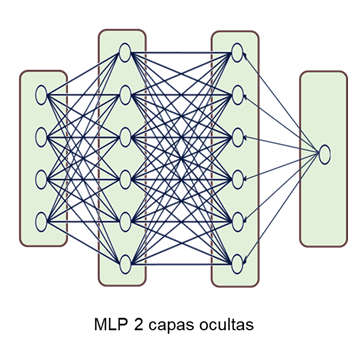

### Ejercicio 9: Entrenar el modelo

Entrena el modelo para 1000 epochs y guarda los resultados del entrenamiento en una variable llamada `history`.
Emplea en el entrenamiento un 20% de los datos para validación, mediante el argumento `validation_split`.

In [31]:
X_train = train_set[features]
y_train = train_set[target]

X_test = test_set[features]
y_test = test_set[target]

In [32]:
history = model.fit(X_train, 
                    y_train,
                    epochs=1000, 
                    validation_split=0.2,
                    verbose=0)

### Ejercicio 10

Visualiza el progreso de entrenamiento del modelo usando las estadísticas almacenadas en el objeto `history`. Muestra en una gráfica la evolución del error en train y validation, y en otra la evolución de la pérdida (loss), también train contra validation.

In [33]:
hist = pd.DataFrame(history.history)
hist['epoch'] = history.epoch
hist.tail()

,loss,mae,mse,val_loss,val_mae,val_mse,epoch
995,4.542496,1.482805,4.542496,5.987487,1.690731,5.987487,995
996,4.548824,1.483908,4.548824,6.016222,1.698964,6.016222,996
997,4.551095,1.484110,4.551095,5.985487,1.688680,5.985487,997
998,4.539569,1.481803,4.539569,6.010673,1.698611,6.010673,998
999,4.551566,1.484067,4.551566,5.982534,1.688001,5.982534,999


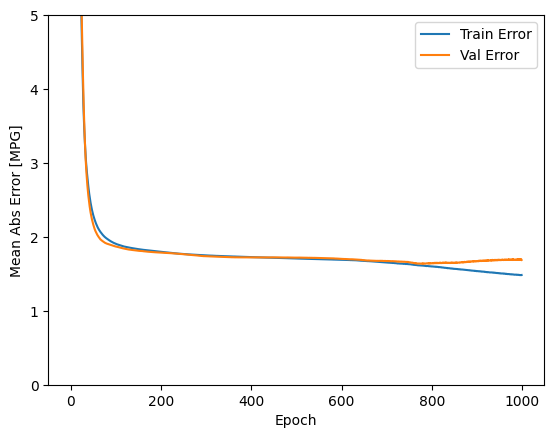

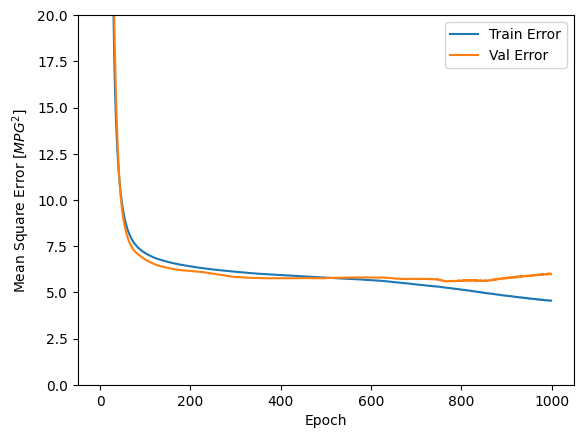

In [34]:
def plot_history(history, error = True):
  hist = pd.DataFrame(history.history)
  hist['epoch'] = history.epoch

  if error:
    plt.figure()
    plt.xlabel('Epoch')
    plt.ylabel('Mean Abs Error [MPG]')
    plt.plot(hist['epoch'], hist['mae'],
            label='Train Error')
    plt.plot(hist['epoch'], hist['val_mae'],
            label = 'Val Error')
    plt.ylim([0,5])
    plt.legend()

    plt.figure()
    plt.xlabel('Epoch')
    plt.ylabel('Mean Square Error [$MPG^2$]')
    plt.plot(hist['epoch'], hist['mse'],
            label='Train Error')
    plt.plot(hist['epoch'], hist['val_mse'],
            label = 'Val Error')
    plt.ylim([0,20])
    plt.legend()
    plt.show()

  else:
    plt.figure()
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.plot(hist['epoch'], hist['loss'],
            label='Train loss')
    plt.plot(hist['epoch'], hist['val_loss'],
            label = 'Val loss')
    plt.legend()
    plt.show()



plot_history(history)

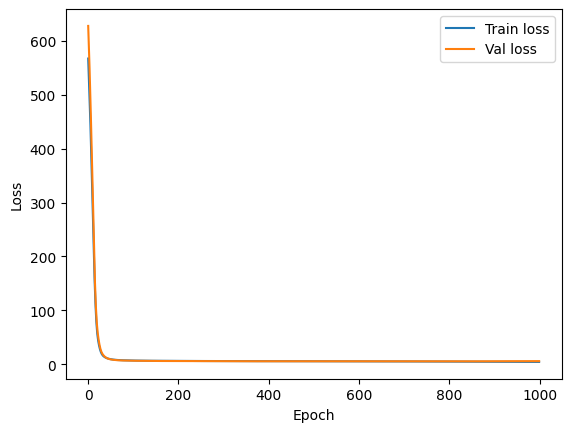

In [35]:
plot_history(history, False)

### Ejercicio 11

Comenta las gráficas anteriores.

*Estos gráficos muestran poca mejora, o incluso degradación, en el error de validación a partir de unas 100 épocas: se queda prácticamente plano en torno a 1.7-1.8 MPG y, en las últimas épocas, el error de train sigue bajando mientras el de validación repunta ligeramente (empieza el overfitting). Actualicemos la llamada `model.fit` para detener automáticamente el entrenamiento cuando la loss de validación no mejore. Utilizaremos un callback `EarlyStopping` que comprueba una condición al final de cada época: si transcurre una cantidad determinada de épocas (`patience`) sin mejora, detiene el entrenamiento.*

### Ejercicio 12

Independientemente de lo comentado en 11, vamos a añadir un callback al entrenamiento. Para ello, construye el modelo otra vez y vuelve a compilarlo (si no lo haces, como ya sabes, el entrenamiento continuará donde lo dejó y el callback no nos servirá de nada). Entrena el modelo con los mismos hiperparámetros del ejercicio 9 y pinta la gráfica de evolución de los errores e interprétala (obtén el MAE medio una vez "estabilizado" el entrenamiento).  

Para el earlystopping utiliza un margen (`patience`) de 20 epochs y quédate con los pesos de la mejor epoch (`restore_best_weights=True`).

Epochs entrenadas: 370 - mejor epoch: 350


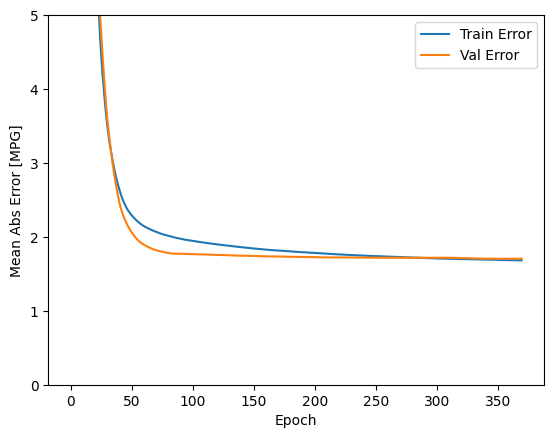

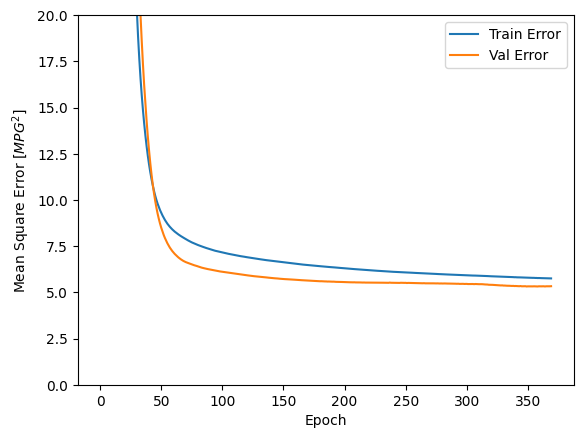

In [36]:
model = keras.Sequential([
    keras.Input(shape = (len(features),)),
    layers.Dense(num_units, activation='relu'),
    layers.Dense(num_units, activation='relu'),
    layers.Dense(1)
])

model.compile(loss='mse',
              optimizer=tf.keras.optimizers.RMSprop(0.001),
              metrics=['mae', 'mse'])

# patience: número de epochs sin mejora antes de parar
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

history = model.fit(X_train,
                    y_train, epochs=1000,
                    validation_split = 0.2,
                    verbose= 0,
                    callbacks=[early_stopping])

print("Epochs entrenadas:", len(history.epoch), "- mejor epoch:", np.argmin(history.history["val_loss"]) + 1)
plot_history(history)

Interpreta el gráfico

*Con el early stopping el entrenamiento se detiene mucho antes de las 1000 épocas (ver la salida: épocas entrenadas y mejor época). A partir de la época 100 aproximadamente el error de validación está estabilizado y las mejoras posteriores son mínimas, así que no merecía la pena entrenar tantas épocas.*

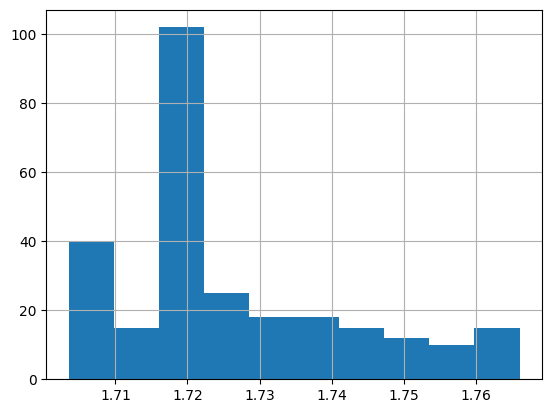

In [37]:
hist = pd.DataFrame(history.history)
epoca_estable = 100
hist[epoca_estable:].val_mae.hist();

In [38]:
mae_val = hist[epoca_estable:].val_mae.mean()
mae_val

1.7258499750384577

*Una vez estabilizado el entrenamiento, el error absoluto medio en validación está en torno a 1.7 MPG. ¿Es esto bueno? Le dejaremos la decisión a "negocio"*

### Ejercicio 13

Veamos lo bien que generaliza el modelo con el conjunto de **test**. Esto nos da una idea de cómo funcionará cuando lo usemos en el mundo real. Utiliza el método `evaluate` con los datos de test normalizados y sus labels.

El método evaluate devolverá tres valores: loss, mae y mse.

In [39]:
loss, mae, mse = model.evaluate(X_test, y_test, verbose=1)

print("Testing set Mean Abs Error: {:5.2f} MPG".format(mae))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 4.9302 - mae: 1.6320 - mse: 4.9302
Testing set Mean Abs Error:  1.68 MPG


*Y su MAPE (error porcentual absoluto medio):*

In [40]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(y_test, model.predict(X_test, verbose = 0).flatten())
print(f"Testing set MAPE: {mape:.1%}")

Testing set MAPE: 7.6%


*Un error porcentual medio algo inferior al 8% en test, coherente con el MAE de ~1.7 MPG que veíamos en validación: el modelo generaliza bien.*

### Ejercicio 14

Dibuja en un scatter plot las predicciones de test vs sus true labels.

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


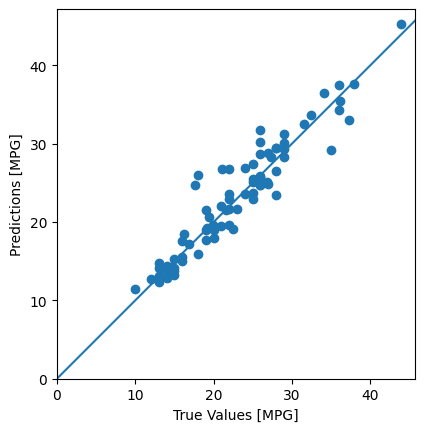

In [41]:
y_pred = model.predict(X_test).flatten() # Hay que aplanar porque devuelve un array de dos dimensiones

plt.scatter(y_test, y_pred)
plt.xlabel('True Values [MPG]')
plt.ylabel('Predictions [MPG]')
plt.axis('equal')
plt.axis('square')
plt.xlim([0,plt.xlim()[1]])
plt.ylim([0,plt.ylim()[1]])
_ = plt.plot([-100, 100], [-100, 100])


*Parece que nuestro modelo predice razonablemente bien. Echemos un vistazo a la distribución de errores.*


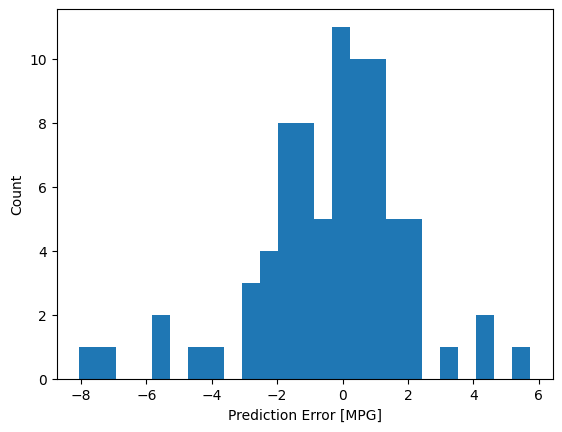

In [42]:
error = y_test - y_pred
plt.hist(error, bins = 25)
plt.xlabel("Prediction Error [MPG]")
_ = plt.ylabel("Count")